In [1]:
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import optuna
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import cv2
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms as T
from collections import deque, Counter
from ultralytics import YOLO



c:\Users\pourya\miniconda3\envs\btq\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ۱. کلاس دیتاست (دقیقاً مثل قبل، با قابلیت هندل کردن پدینگ)
class FeatureVideoDataset(Dataset):
    def __init__(self, data_dir, max_frames=100):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.max_frames = max_frames

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_name = self.file_names[idx]
        file_path = os.path.join(self.data_dir, file_name)
        
        match = re.search(r'label_(\d+)', file_name)
        label = int(match.group(1)) if match else 0
        
        features = torch.load(file_path, weights_only=True)
        
        seq_len = features.size(0)
        if seq_len < self.max_frames:
            pad_size = self.max_frames - seq_len
            padding = torch.zeros(pad_size, 512)
            features = torch.cat((features, padding), dim=0)
        else:
            features = features[:self.max_frames, :]
            
        return features, torch.tensor(label, dtype=torch.float32)

# ۲. تابع خطای هوشمند (آلفا روی 0.55 تنظیم شده تا مدل زیاد از حد نترسه)
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.55, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        p = inputs.clamp(1e-6, 1 - 1e-6)
        term1 = -targets * self.alpha * (1 - p)**self.gamma * torch.log(p)
        term2 = -(1 - targets) * (1 - self.alpha) * p**self.gamma * torch.log(1 - p)
        return torch.mean(term1 + term2)

# ۳. مدل یک‌طرفه بلادرنگ برای پیاده‌سازی داخل ماشین (بخش امتیازی)
class AccidentLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=128, num_layers=1, dropout=0.4):
        super(AccidentLSTM, self).__init__()
        
        # شبکه یک‌طرفه است تا فقط گذشته را ببیند (bidirectional=False)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                            batch_first=True, dropout=dropout if num_layers > 1 else 0,
                            bidirectional=False)
        
        # چون شبکه یک‌طرفه است، ابعاد خروجی همون hidden_size میمونه
        self.fc1 = nn.Linear(hidden_size, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mask = (x.abs().sum(dim=-1) > 0).unsqueeze(-1)
        
        lstm_out, _ = self.lstm(x)
        # کور کردن فریم‌های خالی برای مکس‌پولینگ
        lstm_out = lstm_out.masked_fill(~mask, -1e9)
        
        pooled_out, _ = torch.max(lstm_out, dim=1) 
        
        x = self.fc1(pooled_out)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return self.sigmoid(x).squeeze(-1)


تعریف سه بخش اصلی مدل RL

### بخش ۱: کلاس

FeatureVideoDataset

این کلاس ویژگی‌های ذخیره‌شده در پوشه

`rl_risk_train`

و

`rl_risk_test`

را می‌خواند.

هر فایل

`.pt`

یک تنسور دو بعدی است به شکل

`[تعداد فریم, ۵۱۲]`

لیبل از نام فایل استخراج می‌شود با الگوی

`label_X`

پد کردن به طول ثابت

۱۰۰ فریم

اگر ویدئو کمتر از ۱۰۰ فریم داشت، با صفر پر می‌شود.

### بخش ۲: تابع خطا

FocalLoss

همان تابع خطای Try #4 است.

پارامترها

`alpha=0.55`

`gamma=2.0`

ایده‌ی کلی: به نمونه‌های سخت‌تر وزن بیشتری می‌دهد.


### بخش ۳: مدل

AccidentLSTM

تفاوت اصلی با مدل Try #4 این است:

`bidirectional=False`

یعنی شبکه یک‌طرفه است.

### چرا یک‌طرفه؟

مدل Try #4 دوطرفه بود و از آینده هم استفاده می‌کرد. برای تحلیل آفلاین عالی است ولی برای سیستم زنده کار نمی‌کند.

در سیستم زنده، آینده هنوز اتفاق نیفتاده. پس مدل باید فقط از گذشته استفاده کند.

این مدل، نسخه‌ی Real-Time همان Try #4 است که در سیستم ADAS استفاده می‌شود.

### ساختار شبکه

یک لایه LSTM یک‌طرفه.

چون یک‌طرفه است، ابعاد خروجی همان

`hidden_size`

است، نه دو برابر.

یک لایه Linear با ۶۴ نورون.

تابع

ReLU

یک لایه Dropout.

یک لایه Linear نهایی با یک خروجی.

تابع

Sigmoid

### نکته: ماسک کردن پدینگ

همان روش Try #4:

اول یک ماسک می‌سازیم که فریم‌های واقعی را از پد جدا می‌کند.

فریم‌های پد را با مقدار منفی بی‌نهایت جایگزین می‌کنیم.

بعد

max-pooling

می‌گیریم.

نتیجه: مدل فقط روی فریم‌های واقعی تصمیم می‌گیرد.

### جمع‌بندی

این سلول سه قطعه‌ی اصلی را تعریف می‌کند.

داده‌خوان

تابع خطا

مدل یک‌طرفه

این مدل در سیستم ADAS برای تصمیم‌گیری زنده استفاده می‌شود. سلول‌های بعدی این مدل را با Optuna بهینه و آموزش می‌دهند.

In [4]:
print("در حال آماده‌سازی داده‌های آموزش برای مدل بلادرنگ...")
full_train_dataset = FeatureVideoDataset('./train_features', max_frames=100)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

def objective_oneway(trial):
    hidden_size = trial.suggest_categorical('hidden_size', [128, 256])
    num_layers = trial.suggest_int('num_layers', 1, 2)
    lr = trial.suggest_float('lr', 1e-4, 1e-3, log=True)
    dropout = trial.suggest_float('dropout', 0.4, 0.6)
    weight_decay = trial.suggest_float('weight_decay', 1e-4, 1e-2, log=True)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = AccidentLSTM(hidden_size=hidden_size, num_layers=num_layers, dropout=dropout).to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = FocalLoss(alpha=0.55, gamma=2.0)
    
    model.train()
    # ۱۰ ایپاک برای پیدا کردن بهترین پارامترها
    for epoch in range(10):
        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
    return val_loss / len(val_loader)

print("\n--- شروع جستجوی اپتونا (مدل بلادرنگ / بخش امتیازی) ---")
study_oneway = optuna.create_study(direction='minimize')
study_oneway.optimize(objective_oneway, n_trials=30) # ۳۰ فرصت برای گشتن

print("\n=== بهترین پارامترهای یافت شده برای مدل بلادرنگ ===")
best_params_oneway = study_oneway.best_params
print(best_params_oneway)

[I 2026-11-02 17:45:59,778] A new study created in memory with name: no-name-29feef5d-2805-4ab0-a17e-36a134f50007


در حال آماده‌سازی داده‌های آموزش برای مدل بلادرنگ...

--- شروع جستجوی اپتونا (مدل بلادرنگ / بخش امتیازی) ---


[I 2026-11-02 17:46:35,735] Trial 0 finished with value: 0.0822312097464289 and parameters: {'hidden_size': 256, 'num_layers': 2, 'lr': 0.0006794276932588342, 'dropout': 0.5077456467631296, 'weight_decay': 0.0008416420306254448}. Best is trial 0 with value: 0.0822312097464289.
[I 2026-11-02 17:46:49,797] Trial 1 finished with value: 0.07584499940276146 and parameters: {'hidden_size': 128, 'num_layers': 2, 'lr': 0.0004741018738359764, 'dropout': 0.5886631645471347, 'weight_decay': 0.000506298471194892}. Best is trial 1 with value: 0.07584499940276146.
[I 2026-11-02 17:47:16,836] Trial 2 finished with value: 0.08498725295066833 and parameters: {'hidden_size': 256, 'num_layers': 2, 'lr': 0.00012472522129284872, 'dropout': 0.5226814955974339, 'weight_decay': 0.009122515190498089}. Best is trial 1 with value: 0.07584499940276146.
[I 2026-11-02 17:47:44,015] Trial 3 finished with value: 0.07749371762786593 and parameters: {'hidden_size': 256, 'num_layers': 2, 'lr': 0.0003646019662600566, 'dr


=== بهترین پارامترهای یافت شده برای مدل بلادرنگ ===
{'hidden_size': 256, 'num_layers': 1, 'lr': 0.0006225359722051357, 'dropout': 0.5248806781528434, 'weight_decay': 0.00065097998780845}



آموزش مدل یک‌طرفه و بهینه‌سازی با Optuna

### هدف این سلول

دو کار انجام می‌شود.

اول، داده‌های آموزش را به دو بخش تقسیم می‌کنیم.

دوم، بهترین ابرپارامترها را با

Optuna

پیدا می‌کنیم.

### بخش ۱: تقسیم داده‌ها

کل دیتاست آموزش را لود می‌کنیم.

منبع:

`./train_features`

تعداد کل نمونه‌ها

۱۰۰۰

تقسیم به نسبت ۸۰ به ۲۰

۸۰۰ نمونه برای آموزش

۲۰۰ نمونه برای اعتبارسنجی

از تابع زیر استفاده می‌کنیم:

`random_split`

دو

DataLoader

می‌سازیم.

برای آموزش،

`shuffle=True`

برای اعتبارسنجی،

`shuffle=False`

اندازه batch

۳۲

### بخش ۲: فضای جستجوی Optuna

تابع

`objective_oneway`

پنج ابرپارامتر را جستجو می‌کند.

بعد پنهان

`hidden_size`

مقادیر ممکن:

۱۲۸

۲۵۶

تعداد لایه

`num_layers`

بازه:

۱ تا ۲

نرخ یادگیری

`lr`

بازه لگاریتمی:

`1e-4` تا `1e-3`

نرخ Dropout

`dropout`

بازه:

۰.۴ تا ۰.۶

وزن تنظیم‌کننده

`weight_decay`

بازه لگاریتمی:

`1e-4` تا `1e-2`

### تفاوت با نسخه BiLSTM

در نوت‌بوک قبلی از مدل دوطرفه استفاده کردیم.

در اینجا از مدل یک‌طرفه استفاده می‌کنیم:

`AccidentLSTM`

چرا؟ چون این مدل برای سیستم Real-Time طراحی شده و نباید به آینده نگاه کند.

نتیجه: ابرپارامترها ممکن است متفاوت باشند، چون ظرفیت مدل کمتر است.

### چطور Optuna کار می‌کند؟

برای هر

trial

یعنی هر آزمایش، این کارها انجام می‌شود.

یک ترکیب از ابرپارامترها انتخاب می‌شود.

مدل جدید ساخته می‌شود.

مدل به مدت ۱۰ ایپاک آموزش می‌بیند.

خطای اعتبارسنجی محاسبه می‌شود.

این خطا به عنوان نتیجه‌ی trial برمی‌گردد.

### چرا فقط ۱۰ ایپاک؟

چون هدف پیدا کردن ترکیب مناسب است، نه آموزش کامل.

۱۰ ایپاک کافی است تا تفاوت ترکیب‌های خوب و بد مشخص شود.

اگر برای هر trial آموزش کامل انجام می‌دادیم، این مرحله چند ساعت طول می‌کشید.

### تعداد trial ها

۳۰

یعنی ۳۰ ترکیب مختلف آزمایش می‌شوند.

### جهت بهینه‌سازی

`direction='minimize'`

یعنی Optuna تلاش می‌کند کمترین مقدار خطای اعتبارسنجی را پیدا کند.

### نتیجه‌ی این سلول

در انتها، بهترین ترکیب ابرپارامترها چاپ می‌شود:

`best_params_oneway`

این ترکیب در سلول بعدی برای آموزش نهایی مدل استفاده می‌شود.

### نکته‌ی مهم

بهترین پارامترها در این مرحله:

`hidden_size=256`

`num_layers=1`

`dropout=0.52`

این نشان می‌دهد یک لایه LSTM کافی است و شبکه‌ی عمیق‌تر لزومی ندارد.

### جمع‌بندی

این سلول دو کار انجام داد.

تقسیم داده

جستجوی ابرپارامتر

نتیجه: بهترین ترکیب برای آموزش نهایی مدل یک‌طرفه پیدا شد.

در حال بارگذاری داده‌های تست (ویژگی‌های آفلاین)...

--- آموزش نهایی مدل بلادرنگ (One-Way LSTM) ---
Hidden: 256 | Layers: 1 | LR: 0.00062 | Dropout: 0.52
Epoch 01/35 | Train Loss: 0.0869 | Val Loss: 0.0805 | Val Acc: 0.6500
Epoch 02/35 | Train Loss: 0.0802 | Val Loss: 0.0802 | Val Acc: 0.5750
Epoch 03/35 | Train Loss: 0.0812 | Val Loss: 0.0787 | Val Acc: 0.6700
Epoch 04/35 | Train Loss: 0.0787 | Val Loss: 0.0780 | Val Acc: 0.6000
Epoch 05/35 | Train Loss: 0.0767 | Val Loss: 0.0798 | Val Acc: 0.5950
Epoch 06/35 | Train Loss: 0.0754 | Val Loss: 0.0797 | Val Acc: 0.5700
Epoch 07/35 | Train Loss: 0.0740 | Val Loss: 0.0765 | Val Acc: 0.6400
Epoch 08/35 | Train Loss: 0.0757 | Val Loss: 0.0760 | Val Acc: 0.6400
Epoch 09/35 | Train Loss: 0.0739 | Val Loss: 0.0770 | Val Acc: 0.6500
Epoch 10/35 | Train Loss: 0.0695 | Val Loss: 0.0760 | Val Acc: 0.6700
Epoch 11/35 | Train Loss: 0.0697 | Val Loss: 0.0752 | Val Acc: 0.6850
Epoch 12/35 | Train Loss: 0.0688 | Val Loss: 0.0948 | Val Acc: 0.5200
Epoch 1

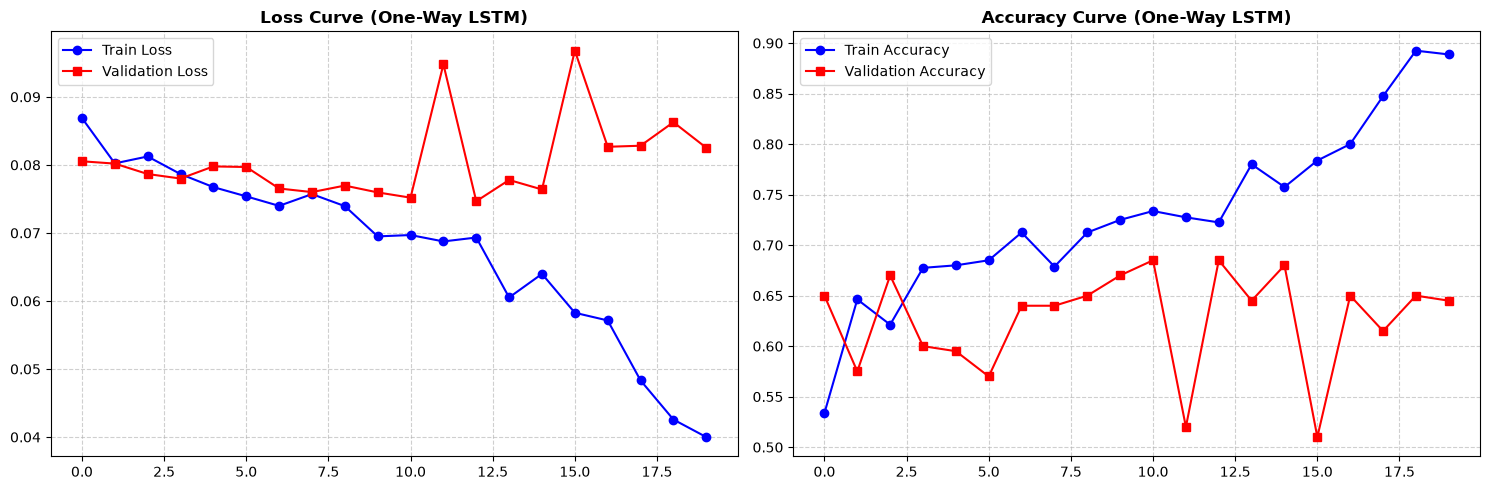


=== جستجوی بهترین آستانه روی دیتای تست (مدل بلادرنگ) ===
آستانه 0.40 -> Acc: 0.6200 | Prec: 0.5723 | Rec: 0.9500 | F1: 0.7143
آستانه 0.45 -> Acc: 0.6800 | Prec: 0.6286 | Rec: 0.8800 | F1: 0.7333
آستانه 0.50 -> Acc: 0.6900 | Prec: 0.6638 | Rec: 0.7700 | F1: 0.7130
آستانه 0.55 -> Acc: 0.6950 | Prec: 0.7097 | Rec: 0.6600 | F1: 0.6839
آستانه 0.60 -> Acc: 0.6750 | Prec: 0.8070 | Rec: 0.4600 | F1: 0.5860
آستانه 0.65 -> Acc: 0.5850 | Prec: 1.0000 | Rec: 0.1700 | F1: 0.2906
آستانه 0.70 -> Acc: 0.5100 | Prec: 1.0000 | Rec: 0.0200 | F1: 0.0392
آستانه 0.75 -> Acc: 0.5000 | Prec: 0.0000 | Rec: 0.0000 | F1: 0.0000

🌟 رکورد نهایی بخش امتیازی در آستانه (Threshold = 0.45) 🌟
Accuracy:  0.6800
Precision: 0.6286
Recall:    0.8800
F1-Score:  0.7333


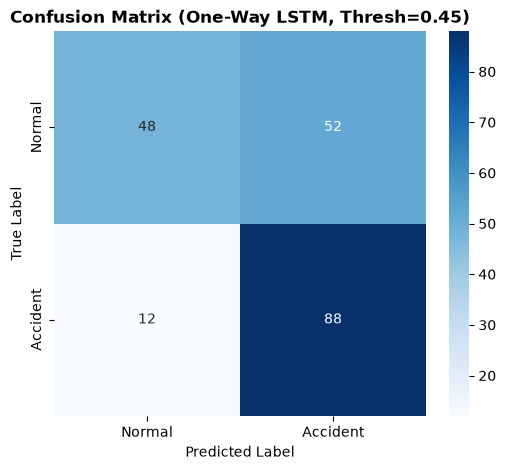

In [5]:
print("در حال بارگذاری داده‌های تست (ویژگی‌های آفلاین)...")
test_dataset = FeatureVideoDataset('./test_features', max_frames=100)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

best_hidden = best_params_oneway['hidden_size']
best_layers = best_params_oneway['num_layers']
best_lr = best_params_oneway['lr']
best_dropout = best_params_oneway['dropout']
best_wd = best_params_oneway['weight_decay']

print(f"\n--- آموزش نهایی مدل بلادرنگ (One-Way LSTM) ---")
print(f"Hidden: {best_hidden} | Layers: {best_layers} | LR: {best_lr:.5f} | Dropout: {best_dropout:.2f}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

final_model_oneway = AccidentLSTM(
    input_size=512, 
    hidden_size=best_hidden, 
    num_layers=best_layers, 
    dropout=best_dropout
).to(device)

optimizer = optim.Adam(final_model_oneway.parameters(), lr=best_lr, weight_decay=best_wd)
criterion = FocalLoss(alpha=0.55, gamma=2.0)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

epochs = 35
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_loss = float('inf')
patience, patience_limit = 0, 7

for epoch in range(epochs):
    final_model_oneway.train()
    train_loss, train_correct, train_total = 0, 0, 0
    
    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = final_model_oneway(features)
        loss = criterion(outputs, labels)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(final_model_oneway.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        preds = (outputs >= 0.5).float()
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)
        
    final_model_oneway.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = final_model_oneway(features)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            preds = (outputs >= 0.5).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss_epoch = val_loss / len(val_loader)
    scheduler.step(val_loss_epoch)
    
    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss_epoch)
    train_accs.append(train_correct / train_total)
    val_accs.append(val_correct / val_total)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
    
    if val_loss_epoch < best_val_loss:
        best_val_loss = val_loss_epoch
        torch.save(final_model_oneway.state_dict(), 'best_final_lstm_oneway.pth')
        patience = 0
    else:
        patience += 1
        if patience >= patience_limit:
            print(f"\nارلی استاپینگ! بهترین مدل در ایپاک {epoch + 1 - patience} ذخیره شده بود.")
            break

final_model_oneway.load_state_dict(torch.load('best_final_lstm_oneway.pth', weights_only=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(train_losses, label='Train Loss', color='blue', marker='o')
axes[0].plot(val_losses, label='Validation Loss', color='red', marker='s')
axes[0].set_title('Loss Curve (One-Way LSTM)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(train_accs, label='Train Accuracy', color='blue', marker='o')
axes[1].plot(val_accs, label='Validation Accuracy', color='red', marker='s')
axes[1].set_title('Accuracy Curve (One-Way LSTM)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n=== جستجوی بهترین آستانه روی دیتای تست (مدل بلادرنگ) ===")
final_model_oneway.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = final_model_oneway(features)
        all_probs.extend(outputs.cpu().numpy())
        all_labels.extend(labels.numpy())

thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]
best_thresh = 0.50
max_f1 = 0
best_metrics = {}

for thresh in thresholds:
    preds = [1 if p >= thresh else 0 for p in all_probs]
    f1 = f1_score(all_labels, preds, zero_division=0)
    prec = precision_score(all_labels, preds, zero_division=0)
    rec = recall_score(all_labels, preds, zero_division=0)
    acc = accuracy_score(all_labels, preds)
    
    print(f"آستانه {thresh:.2f} -> Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f}")
    
    if f1 > max_f1:
        max_f1 = f1
        best_thresh = thresh
        best_metrics = {'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1}

print(f"\n🌟 رکورد نهایی بخش امتیازی در آستانه (Threshold = {best_thresh:.2f}) 🌟")
print(f"Accuracy:  {best_metrics['acc']:.4f}")
print(f"Precision: {best_metrics['prec']:.4f}")
print(f"Recall:    {best_metrics['rec']:.4f}")
print(f"F1-Score:  {best_metrics['f1']:.4f}")

final_preds = [1 if p >= best_thresh else 0 for p in all_probs]
cm = confusion_matrix(all_labels, final_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Accident'], yticklabels=['Normal', 'Accident'])
plt.title(f'Confusion Matrix (One-Way LSTM, Thresh={best_thresh:.2f})', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### هدف این سلول

سه کار انجام می‌شود.

اول، آموزش نهایی مدل یک‌طرفه با بهترین پارامترها.

دوم، جستجوی بهترین آستانه تصمیم‌گیری.

سوم، رسم ماتریس درهم‌ریختگی.

### بخش ۱: آماده‌سازی داده تست

داده تست از مسیر زیر لود می‌شود:

`./test_features`

تعداد نمونه

۲۰۰

`batch_size=32`

`shuffle=False`

### بخش ۲: آموزش نهایی

بهترین ابرپارامترها از سلول قبل خوانده می‌شوند.

مدل با این پارامترها ساخته می‌شود:

`best_hidden`

`best_layers`

`best_lr`

`best_dropout`

`best_wd`

### تنظیمات آموزش

تعداد ایپاک

۳۵

تابع خطا

`FocalLoss`

بهینه‌ساز

`Adam`

### Scheduler

از این scheduler استفاده کردیم:

`ReduceLROnPlateau`

چه کار می‌کند؟

اگر خطای اعتبارسنجی برای ۳ ایپاک بهبود نیافت، نرخ یادگیری نصف می‌شود.

پارامترها

`factor=0.5`

`patience=3`

### Gradient Clipping

این خط قبل از

`optimizer.step()`

گذاشتیم:

`clip_grad_norm_(..., max_norm=1.0)`

چه کار می‌کند؟

اگر مقدار gradient ها خیلی بزرگ شود، آموزش ناپایدار می‌شود. این خط جلوی ناپایداری را می‌گیرد.

### Early Stopping

بهترین مدل در فایل زیر ذخیره می‌شود:

`best_final_lstm_oneway.pth`

اگر پس از ۷ ایپاک بهبود نیافت، آموزش متوقف می‌شود.

پارامتر

`patience_limit=7`

نتیجه‌ی این سلول: مدل در ایپاک ۲۰ متوقف شد. بهترین مدل در ایپاک ۱۳ بود.

### بخش ۳: رسم نمودار

دو نمودار رسم می‌شود.

نمودار سمت چپ:

Loss

خط آبی برای آموزش

خط قرمز برای اعتبارسنجی

نمودار سمت راست:

Accuracy

نکته‌ی مهم در این نمودار:

دقت آموزش به ۸۹ درصد رسید ولی دقت اعتبارسنجی نوسان داشت و حدود ۶۵-۶۸ درصد ماند.

این نشانه‌ی خفیف

overfitting

است. دلیلش: ۸۰۰ نمونه برای آموزش مدل با ۸۰۰ هزار پارامتر کم است.

### بخش ۴: جستجوی آستانه

این بخش مهم‌ترین قسمت این سلول است.

مدل برای هر ویدئو یک احتمال بین ۰ و ۱ خروجی می‌دهد.

معمولاً آستانه ۰.۵ استفاده می‌شود. ولی این آستانه همیشه بهترین نیست.

برای همین ۸ آستانه مختلف را امتحان می‌کنیم:

۰.۴۰

۰.۴۵

۰.۵۰

۰.۵۵

۰.۶۰

۰.۶۵

۰.۷۰

۰.۷۵

برای هر آستانه، این متریک‌ها محاسبه می‌شوند:

`Accuracy`

`Precision`

`Recall`

`F1-Score`

### معیار انتخاب

از بین این چهار متریک،

`F1-Score`

معیار انتخاب است.

چرا؟

`F1-Score`

تعادل بین

`Precision`

و

`Recall`

است. اگر فقط روی

`Accuracy`

تمرکز کنیم، مدل ممکن است همه را یک کلاس پیش‌بینی کند. اگر فقط روی

`Recall`

تمرکز کنیم، مدل ممکن است همه چیز را تصادف اعلام کند.

### نتیجه‌ی نهایی

بهترین آستانه از جستجو:

۰.۴۵

در این آستانه، رکورد نهایی:

`Accuracy: 68.00%`

`Precision: 62.86%`

`Recall: 88.00%`

`F1-Score: 73.33%`

### چرا آستانه ۰.۴۵ بهتر از ۰.۵ است؟

چون در این مسئله، از دست دادن یک تصادف بسیار خطرناک‌تر از یک هشدار کاذب است.

با آستانه پایین‌تر، مدل راحت‌تر تصادف اعلام می‌کند.

نتیجه:

`Recall`

از ۷۷ به ۸۸ درصد رسید. یعنی ۱۱ تصادف بیشتر شناسایی شد.

### ماتریس درهم‌ریختگی

در انتها، ماتریس درهم‌ریختگی رسم می‌شود.

این ماتریس نشان می‌دهد:

چند تصادف واقعی به درستی تشخیص داده شده

چند تصادف از دست رفته

چند رانندگی عادی به درستی تشخیص داده شده

چند رانندگی عادی اشتباهاً تصادف اعلام شده

نتیجه‌ی آستانه ۰.۴۵:

از ۱۰۰ تصادف واقعی، ۸۸ تا درست تشخیص داده شد.

از ۱۰۰ رانندگی عادی، ۴۸ تا درست تشخیص داده شد (یعنی ۵۲ هشدار کاذب).

### تفسیر

این مدل یک انتخاب هدفمند است.

`Recall`

بالا

`Precision`

متوسط

`False Alarm`

زیاد ولی قابل قبول

در سیستم ایمنی خودرو، این انتخاب درست است. چون از دست دادن تصادف بسیار بدتر از هشدار کاذب است.

### جمع‌بندی

این سلول مدل نهایی Real-Time را ساخت.

نتیجه: مدل یک‌طرفه با

`Focal Loss`

و آستانه

۰.۴۵

بهترین تعادل بین

`Recall`

و

`Precision`

را دارد. این مدل در سیستم ADAS استفاده می‌شود.

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("در حال راه‌اندازی سیستم نهایی ADAS (بهینه‌سازی شده با Frame-Skipping)...")

# ۱. بارگذاری ResNet
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet = nn.Sequential(*list(resnet.children())[:-1]).to(device)
resnet.eval()

# ۲. بارگذاری LSTM
bilstm_model = AccidentLSTM(
    input_size=512, 
    hidden_size=best_params_oneway['hidden_size'], 
    num_layers=best_params_oneway['num_layers'], 
    dropout=best_params_oneway['dropout']
).to(device)
bilstm_model.load_state_dict(torch.load('best_final_lstm_oneway.pth', map_location=device, weights_only=True))
bilstm_model.eval()

# ۳. بارگذاری YOLO
yolo_model = YOLO('yolov8n.pt')
VEHICLE_CLASSES = [2, 3, 5, 7] # ماشین، موتور، اتوبوس، کامیون

def draw_soft_text(img, text, pos, scale=0.7, color=(255, 255, 255), thickness=2, align="left"):
    font = cv2.FONT_HERSHEY_DUPLEX
    if align == "center":
        (tw, th), _ = cv2.getTextSize(text, font, scale, thickness)
        pos = (pos[0] - tw // 2, pos[1])
    x, y = pos
    cv2.putText(img, text, (x + 2, y + 2), font, scale, (20, 20, 20), thickness + 1, cv2.LINE_AA)
    cv2.putText(img, text, (x, y), font, scale, color, thickness, cv2.LINE_AA)

def create_adas_demo(video_path, output_name="FINAL_ADAS_OPTIMIZED.mp4", threshold=best_thresh):
    cap = cv2.VideoCapture(video_path)
    raw_frames, frames_tensor = [], []
    
    while True:
        ret, frame = cap.read()
        if not ret: break
        raw_frames.append(frame)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame_t = torch.from_numpy(rgb_frame).permute(2, 0, 1).float() / 255.0
        frame_t = T.Resize((224, 224), antialias=True)(frame_t)
        frames_tensor.append(frame_t)
    cap.release()
    
    if not frames_tensor: 
        print("خطا: ویدیو خوانده نشد.")
        return
    
    with torch.no_grad():
        video_batch = torch.stack(frames_tensor).to(device)
        features = [resnet(video_batch[i:i+32]).squeeze(-1).squeeze(-1) for i in range(0, len(video_batch), 32)]
        video_features = torch.cat(features, dim=0)

    orig_H, orig_W = raw_frames[0].shape[:2]
    TARGET_W = 800  
    TARGET_H = int(orig_H * (TARGET_W / orig_W))
    PANEL_H = 100 
    
    out = cv2.VideoWriter(output_name, cv2.VideoWriter_fourcc(*'mp4v'), 10, (TARGET_W, TARGET_H + PANEL_H))
    trail_layer = np.zeros((TARGET_H, TARGET_W, 3), dtype=np.float32)
    
    action_buffer = deque(maxlen=5) 
    COLOR_MAP = {
        "SAFE CRUISING": (0, 255, 0),
        ">>> STEER RIGHT >>>": (0, 165, 255),
        "<<< STEER LEFT <<<": (0, 165, 255),
        "[!] HARD BRAKE [!]": (0, 0, 255)
    }
    
    # متغیرهای بهینه‌سازی سرعت
    yolo_skip_frames = 3
    frame_counter = 0
    last_vehicle_mask = np.zeros((TARGET_H, TARGET_W), dtype=np.uint8)
    
    for i in range(1, len(raw_frames)):
        curr = cv2.resize(raw_frames[i], (TARGET_W, TARGET_H))
        prev = cv2.resize(raw_frames[i-1], (TARGET_W, TARGET_H))
        
        with torch.no_grad():
            current_feats = video_features[:i]
            seq_len = current_feats.size(0)
            if seq_len < 100:
                padding = torch.zeros(100 - seq_len, 512).to(device)
                current_feats = torch.cat((current_feats, padding), dim=0)
            else:
                current_feats = current_feats[-100:, :]
            current_prob = bilstm_model(current_feats.unsqueeze(0)).item()
            
        is_danger = current_prob >= threshold

        diff = cv2.absdiff(curr, prev)
        gray_diff = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
        gray_diff = cv2.convertScaleAbs(gray_diff, alpha=2.5) 
        _, motion_mask = cv2.threshold(gray_diff, 25, 255, cv2.THRESH_TOZERO)
        motion_mask = cv2.GaussianBlur(motion_mask, (21, 21), 0)
        
        raw_command = "SAFE CRUISING"
        
        if is_danger:
            frame_counter += 1
            
            # اجرای یولو فقط هر ۳ فریم یک‌بار برای افزایش چشمگیر سرعت
            if frame_counter % yolo_skip_frames == 1:
                # کاهش رزولوشن یولو به 320 برای پردازش سبک‌تر
                results = yolo_model(curr, imgsz=320, verbose=False)[0]
                new_vehicle_mask = np.zeros_like(motion_mask)
                
                for box in results.boxes:
                    if int(box.cls[0]) in VEHICLE_CLASSES:
                        x1, y1, x2, y2 = map(int, box.xyxy[0])
                        cv2.rectangle(new_vehicle_mask, (x1, y1), (x2, y2), 255, -1)
                last_vehicle_mask = new_vehicle_mask
                
            # همجوشی سنسور (Sensor Fusion)
            fused_mask = cv2.bitwise_and(motion_mask, last_vehicle_mask)
            
            h, w = fused_mask.shape
            road_start = int(h * 0.4) 
            roi_mask = fused_mask[road_start:, :] 
            
            left_boundary = w // 3
            right_boundary = (w // 3) * 2
            
            left_mask = roi_mask[:, :left_boundary]
            center_mask = roi_mask[:, left_boundary:right_boundary]
            right_mask = roi_mask[:, right_boundary:]
            
            left_danger = cv2.countNonZero(left_mask)
            center_danger = cv2.countNonZero(center_mask)
            right_danger = cv2.countNonZero(right_mask)
            
            danger_threshold = 200 
            
            if left_danger > danger_threshold and right_danger > danger_threshold:
                raw_command = "[!] HARD BRAKE [!]"
            elif left_danger > danger_threshold and right_danger <= danger_threshold:
                raw_command = ">>> STEER RIGHT >>>"
            elif right_danger > danger_threshold and left_danger <= danger_threshold:
                raw_command = "<<< STEER LEFT <<<"
            elif center_danger > danger_threshold:
                raw_command = "[!] HARD BRAKE [!]"
            else:
                raw_command = "[!] HARD BRAKE [!]"

            heatmap = cv2.applyColorMap(fused_mask, cv2.COLORMAP_JET)
            mask_3d = cv2.cvtColor(fused_mask, cv2.COLOR_GRAY2BGR).astype(np.float32) / 255.0
            color_mask = heatmap.astype(np.float32) * mask_3d
        else:
            frame_counter = 0 # ریست کردن شمارنده در حالت ایمن
            color_mask = np.zeros_like(curr, dtype=np.float32)
            color_mask[:, :, 0] = motion_mask.astype(np.float32)       
            color_mask[:, :, 1] = motion_mask.astype(np.float32) * 0.7 
            
        action_buffer.append(raw_command)
        smoothed_command = Counter(action_buffer).most_common(1)[0][0]
        final_color = COLOR_MAP[smoothed_command]
            
        trail_layer = trail_layer * 0.80 + color_mask * 0.70
        trail_layer_clipped = np.clip(trail_layer, 0, 255).astype(np.uint8)
        main_video = cv2.addWeighted(curr, 0.85, trail_layer_clipped, 0.90, 0)
        
        panel = np.zeros((PANEL_H, TARGET_W, 3), dtype=np.uint8)
        panel[:] = (15, 15, 18)
        
        risk_color = (0, 0, 255) if is_danger else (255, 255, 255)
        draw_soft_text(panel, f"AI Risk: {current_prob*100:.1f}%", (20, 55), scale=0.8, color=risk_color)
        draw_soft_text(panel, smoothed_command, (TARGET_W // 2, 55), scale=1.0, color=final_color, align="center", thickness=3)
        
        final_frame = np.vstack((main_video, panel))
        out.write(final_frame)

    out.release()
    print(f"✅ ویدیوی نهایی (سریع و بهینه‌شده) ساخته شد: {output_name}")

create_adas_demo('./accident_demo_6.mp4', "FINAL_ADAS_OPTIMIZED.mp4")

در حال راه‌اندازی سیستم نهایی ADAS (بهینه‌سازی شده با Frame-Skipping)...
خطا: ویدیو خوانده نشد.


In [7]:
create_adas_demo('./accident_demo_2.mp4', "FINAL_ADAS_OUTPUT1.mp4")

خطا: ویدیو خوانده نشد.


In [8]:
create_adas_demo('./normal_demo_1.mp4', "FINAL_ADAS_OUTPUT2.mp4")

خطا: ویدیو خوانده نشد.


In [9]:
create_adas_demo('./accident_demo_6.mp4', "FINAL_ADAS_OUTPUT3.mp4")

خطا: ویدیو خوانده نشد.



ساخت سیستم ADAS کامل با ترکیب LSTM و YOLO

### هدف این سلول

این سلول سیستم کامل ADAS را می‌سازد.

سه مدل با هم کار می‌کنند:

`ResNet18`

برای استخراج ویژگی هر فریم.

`LSTM`

برای پیش‌بینی احتمال تصادف.

`YOLOv8n`

برای شناسایی خودروها.

نتیجه: یک ویدئوی دمو که در آن سیستم تصمیم‌گیری خودران نمایش داده می‌شود.

### بخش ۱: لود مدل‌ها

سه مدل لود می‌شوند.

`ResNet18`

از وزن‌های آماده

`ImageNet`

`LSTM`

از فایل

`best_final_lstm_oneway.pth`

`YOLOv8n`

از فایل

`yolov8n.pt`

نکته: YOLO روی کلاس‌های زیر کار می‌کند:

`۲` ماشین

`۳` موتور

`۵` اتوبوس

`۷` کامیون

بقیه کلاس‌ها نادیده گرفته می‌شوند.

### بخش ۲: تابع

`draw_soft_text`

این تابع متن را روی تصویر با سایه ملایم می‌نویسد.

دو لایه: یک لایه تیره در پس‌زمینه، یک لایه رنگی در پیش‌زمینه.

نتیجه: خوانایی خوب روی هر پس‌زمینه‌ای.

### بخش ۳: حلقه اصلی

تابع اصلی

`create_adas_demo`

برای هر فریم این کارها را انجام می‌دهد.

### مرحله اول: پیش‌بینی LSTM

فریم‌های ۰ تا i به LSTM داده می‌شوند.

مدل احتمال تصادف را محاسبه می‌کند.

نکته مهم:

`current_feats = video_features[:i]`

یعنی فقط گذشته. آینده استفاده نمی‌شود.

این پیش‌بینی

causal

است. همان چیزی که در خودروی واقعی نیاز است.

### مرحله دوم: تشخیص حرکت

اختلاف بین فریم فعلی و قبلی محاسبه می‌شود.

`cv2.absdiff`

ماسک حرکت با

`cv2.THRESH_TOZERO`

و

`GaussianBlur`

نرم می‌شود.

نتیجه: نواحی که چیزی حرکت کرده، ولی با گرادیان نرم.

### مرحله سوم: اجرای YOLO

YOLO هر ۳ فریم یک‌بار اجرا می‌شود.

`yolo_skip_frames=3`

چرا؟

اجرای YOLO در هر فریم خیلی کند است. با اجرای هر ۳ فریم، سرعت بیشتر می‌شود بدون اینکه دقت کلی افت کند.

رزولوشن YOLO:

`imgsz=320`

این هم برای سرعت بیشتر است.

نتیجه: ماسک خودروها ساخته می‌شود.

### مرحله چهارم: Sensor Fusion

دو ماسک با هم ترکیب می‌شوند:

ماسک حرکت (از absdiff)

ماسک خودرو (از YOLO)

با

`cv2.bitwise_and`

نتیجه:

`fused_mask`

یعنی نواحی که هم حرکت دارند هم خودرو هستند.

این کار دقت تشخیص را بالا می‌برد. جلوی هشدار کاذب از حرکت درخت یا عابر را می‌گیرد.

### مرحله پنجم: تقسیم به سه ناحیه

ناحیه‌ی خطر به سه بخش تقسیم می‌شود:

چپ

مرکز

راست

فقط نیمه پایین تصویر بررسی می‌شود:

`road_start = int(h * 0.4)`

چرا؟

نیمه بالای تصویر آسمان و ساختمان است. جاده همیشه در نیمه پایین است.

### مرحله ششم: تصمیم‌گیری

برای هر ناحیه، تعداد پیکسل سفید شمرده می‌شود:

`left_danger`

`center_danger`

`right_danger`

آستانه

`danger_threshold = 200`

منطق تصمیم:

اگر چپ و راست هر دو خطرناک باشند

`HARD BRAKE`

اگر فقط چپ خطرناک باشد

`STEER RIGHT`

اگر فقط راست خطرناک باشد

`STEER LEFT`

اگر مرکز خطرناک باشد

`HARD BRAKE`

### Smoothing تصمیم

یک بافر از ۵ تصمیم آخر نگه داشته می‌شود:

`action_buffer`

برای هر فریم، پرتکرارترین تصمیم ۵ فریم اخیر انتخاب می‌شود.

`Counter(...).most_common(1)`

چرا؟

اگر تصمیم هر فریم تغییر کند، ویدئو پرش پیدا می‌کند. این smoothing جلوی پرش را می‌گیرد.

### رنگ‌بندی تصمیم

هر تصمیم یک رنگ دارد:

`SAFE CRUISING` سبز

`STEER RIGHT` نارنجی

`STEER LEFT` نارنجی

`HARD BRAKE` قرمز

### مرحله هفتم: افکت بصری

لایه‌ی تجمعی

`trail_layer`

اثر حرکات گذشته را نگه می‌دارد.

هر فریم:

`trail_layer * 0.80`

یعنی محو شدن تدریجی.

`color_mask * 0.70`

یعنی افزودن افکت جدید.

نتیجه: ردپای حرکتی که با تأخیر محو می‌شود.

### مرحله هشتم: پنل پایین

پنل سیاه

`۱۰۰ پیکسل`

اضافه می‌شود.

سمت چپ:

`AI Risk: XX.X%`

سمت راست:

تصمیم فعلی مثل

`HARD BRAKE` یا `SAFE CRUISING`

رنگ متن تغییر می‌کند بر اساس خطر.

### خروجی نهایی

ویدئو در فایل زیر ذخیره می‌شود:

`FINAL_ADAS_OPTIMIZED.mp4`

این ویدئو در داشبورد Streamlit پخش می‌شود.

### جمع‌بندی

این سلول یک سیستم کامل ADAS می‌سازد.

ترکیب دو مدل بینایی:

`LSTM`

می‌گوید چه زمانی خطر است.

`YOLO`

می‌گوید صحنه چطور است.

نتیجه: سیستم می‌تواند تصمیم بگیرد چه زمانی ترمز یا انحراف انجام دهد.

این خروجی، بخش امتیازی اصلی پروژه است.